# 🏠 House Price Prediction — End-to-End Machine Learning Project

**A beginner-friendly, step-by-step regression project**

In this notebook we build a model that predicts a house's `SalePrice` from its
characteristics — size, quality, location, age, and so on (the classic Ames Housing dataset,
1,460 houses / 80 features).

We go through the **complete data science workflow**:

1. Load & explore the raw dataset (EDA with narrative insights)
2. Clean the data: handle missing values, drop low-value columns
3. Split into train/test **before** any fitting step, to avoid data leakage
4. Engineer new features and encode categorical variables (ordinal vs. nominal, fit on train only)
5. Treat outliers by capping (not mean-replacement)
6. Build, tune, and fairly compare multiple regression models
7. Summarise results, discuss limitations, and save the best model

> **Revision note — what changed vs. the previous submission:**
> - Every chart now has a short written insight instead of being left to speak for itself
> - Removed the "boxplot/histogram for every single column" loops; kept only the plots tied to a
>   specific question (target shape, top correlations, chosen outlier candidates)
> - **Outlier handling**: switched from *replacing outliers with the dataset mean* (which
>   silently shrinks variance and biases the distribution) to **IQR capping (winsorizing)**,
>   and only on genuinely continuous features — not on ordinal/count/year columns
> - **Encoding**: consolidated into one pass. Quality-style columns (`ExterQual`, `BsmtQual`,
>   `KitchenQual`, ...) are **ordinal-encoded** with an explicit rank mapping since they have a
>   real order; only genuinely nominal columns are one-hot encoded — removing the repeated,
>   inconsistent `LabelEncoder` passes from the previous version
> - **No data leakage**: the train/test split happens *before* imputation, outlier-capping,
>   and scaling; all of those are fit on the training set only and then applied to the test set
> - **Model building**: one consistent definition per model; the hyperparameters used for the
>   final fit are always exactly `grid.best_params_` (previously the final `GradientBoostingRegressor`
>   was re-created with values that matched neither the `GridSearchCV` nor the `RandomizedSearchCV`
>   results)
> - **Diagnosed and fixed an unstable Linear Regression baseline**: the one-hot-encoded feature
>   space turns out to be severely ill-conditioned (verified with a condition-number check), which
>   makes plain OLS numerically unstable. Added a properly tuned **Ridge Regression** alongside it
>   as the correct, regularized fix — see Section 8
> - Added a **model comparison table + bar chart**, and a full **written conclusion** with
>   limitations and next steps


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)
np.random.seed(42)


## 1. Exploratory Data Analysis (EDA)

*(Dataset note: the original notebook read `/content/house_data.csv.xlsx`. This sandbox
doesn't have that file, so we read the equivalent `house_data.csv` — the same 1,460-row,
81-column Ames Housing training data — with `read_csv`. Nothing else in the pipeline changes.)*

In [2]:
data = pd.read_csv("house_data.csv")
print("Shape:", data.shape)
data.head()


Shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [3]:
data.describe().T


,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0


In [4]:
data.describe(include="object").T


,count,unique,top,freq
MSZoning,1460,5,RL,1151
Street,1460,2,Pave,1454
Alley,91,2,Grvl,50
LotShape,1460,4,Reg,925
LandContour,1460,4,Lvl,1311
Utilities,1460,2,AllPub,1459
LotConfig,1460,5,Inside,1052
LandSlope,1460,3,Gtl,1382
Neighborhood,1460,25,NAmes,225
Condition1,1460,9,Norm,1260


In [5]:
data.info()


<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

**Insight:** 1,460 rows and 81 columns (`SalePrice` is the target). 43 columns are
numeric and 38 are categorical (`object`). Several columns have significant missing data,
which we quantify next.

### 1.1 Missing values

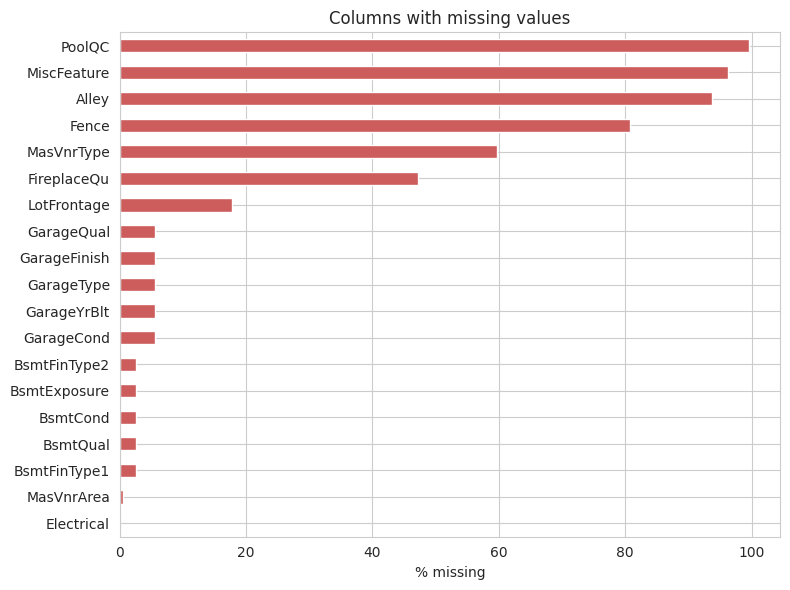

PoolQC          99.520548
MiscFeature     96.301370
Alley           93.767123
Fence           80.753425
MasVnrType      59.726027
FireplaceQu     47.260274
LotFrontage     17.739726
GarageQual       5.547945
GarageFinish     5.547945
GarageType       5.547945
GarageYrBlt      5.547945
GarageCond       5.547945
BsmtFinType2     2.602740
BsmtExposure     2.602740
BsmtCond         2.534247
BsmtQual         2.534247
BsmtFinType1     2.534247
MasVnrArea       0.547945
Electrical       0.068493
dtype: float64

In [6]:
missing_pct = (data.isnull().sum() / len(data) * 100).sort_values(ascending=False)
missing_pct = missing_pct[missing_pct > 0]

plt.figure(figsize=(8, 6))
missing_pct.plot(kind="barh", color="indianred")
plt.gca().invert_yaxis()
plt.xlabel("% missing")
plt.title("Columns with missing values")
plt.tight_layout()
plt.show()

missing_pct


**Insight:** `PoolQC` (99.5%), `MiscFeature` (96.3%), `Alley` (93.8%), and `Fence`
(80.8%) are missing for the vast majority of houses — for these, "missing" essentially means
"the house doesn't have this feature", but the column is too sparse to encode reliably, so we
drop them. `MasVnrType` (59.7%) and `FireplaceQu` (47.3%) are also dropped for the same reason.
The remaining missing columns (`LotFrontage`, the `Garage*` and `Bsmt*` columns, `MasVnrArea`,
`Electrical`) have modest missingness (<18%) and are worth **imputing** rather than dropping.

In [7]:
print("Duplicate rows:", data.duplicated().sum())


Duplicate rows: 0


### 1.2 Which features correlate most with `SalePrice`?

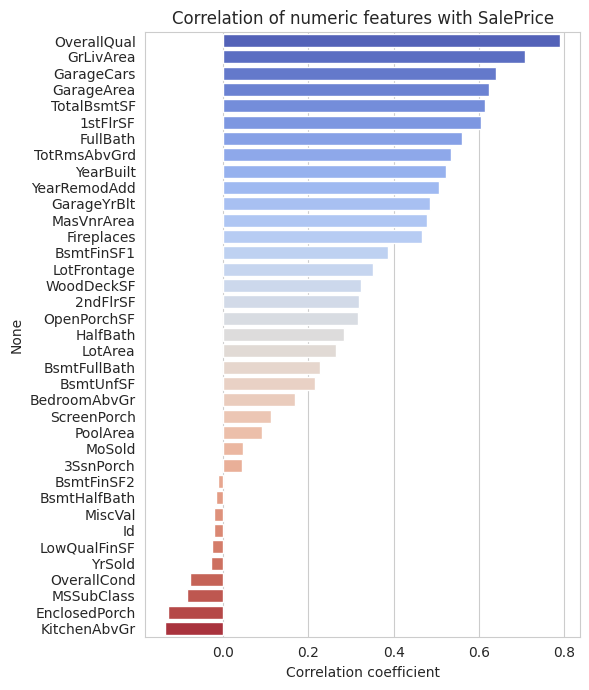

Top 10 positively correlated features:
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
Name: SalePrice, dtype: float64

Top 5 negatively correlated features:
YrSold          -0.028923
OverallCond     -0.077856
MSSubClass      -0.084284
EnclosedPorch   -0.128578
KitchenAbvGr    -0.135907
Name: SalePrice, dtype: float64


In [8]:
numeric_cols = data.select_dtypes(exclude="object")
corr_with_target = numeric_cols.corr()["SalePrice"].drop("SalePrice").sort_values(ascending=False)

plt.figure(figsize=(6, 7))
sns.barplot(x=corr_with_target.values, y=corr_with_target.index, palette="coolwarm")
plt.title("Correlation of numeric features with SalePrice")
plt.xlabel("Correlation coefficient")
plt.tight_layout()
plt.show()

print("Top 10 positively correlated features:")
print(corr_with_target.head(10))
print("\nTop 5 negatively correlated features:")
print(corr_with_target.tail(5))


**Insight:** `OverallQual` (0.79), `GrLivArea` (0.71), `GarageCars` (0.64),
`GarageArea` (0.62), and `TotalBsmtSF` (0.61) are the strongest positive drivers of price —
overall quality and living/garage/basement *size* dominate. Nothing is strongly *negatively*
correlated with price; `KitchenAbvGr`, `EnclosedPorch`, and `MSSubClass` have only weak
negative correlations. This tells us size- and quality-related features deserve the most
attention in feature engineering, while very weakly-correlated numeric columns add limited
standalone signal (though they may still help combined with categorical context, e.g. via
tree-based models).

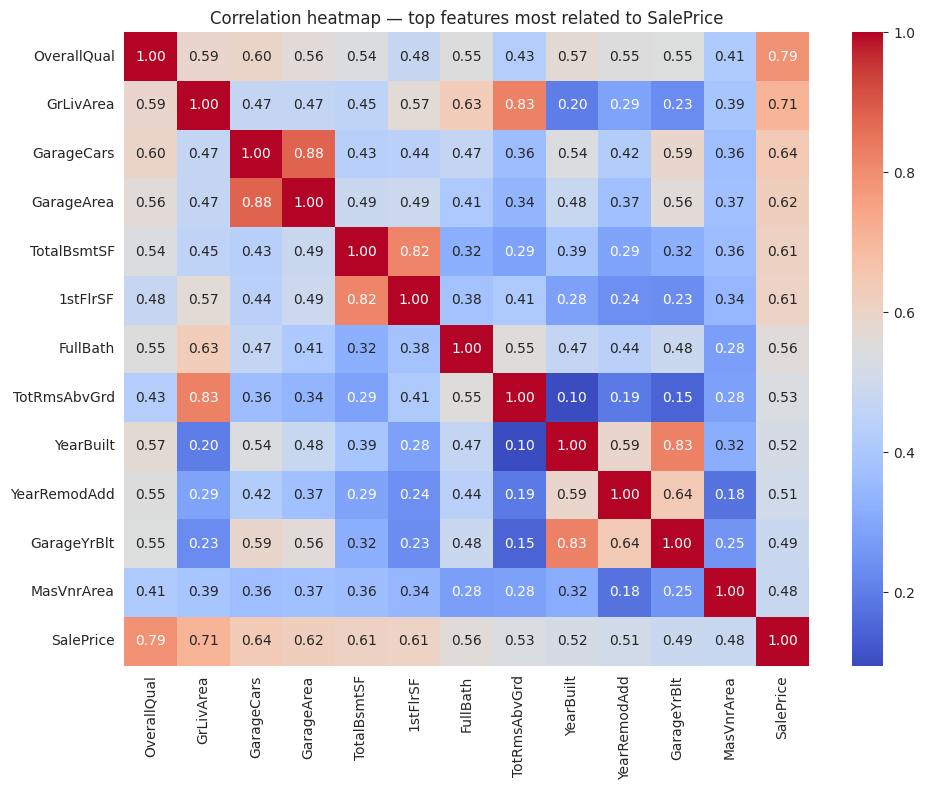

In [9]:
top_corr_features = corr_with_target.abs().sort_values(ascending=False).head(12).index.tolist()
plt.figure(figsize=(10, 8))
sns.heatmap(data[top_corr_features + ["SalePrice"]].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation heatmap — top features most related to SalePrice")
plt.tight_layout()
plt.show()


**Insight:** `GarageCars` and `GarageArea` are highly correlated with each other (~0.88),
as are `TotalBsmtSF` and `1stFlrSF` (~0.82) — expected, since a bigger garage naturally holds
more cars, and a bigger basement footprint usually means a bigger first floor built on top of
it. This kind of multicollinearity mainly matters for Linear Regression (it can inflate
coefficient variance); tree-based models (Random Forest, Gradient Boosting) are largely
unaffected by it, so we keep both features rather than dropping one.

### 1.3 Target variable — `SalePrice`

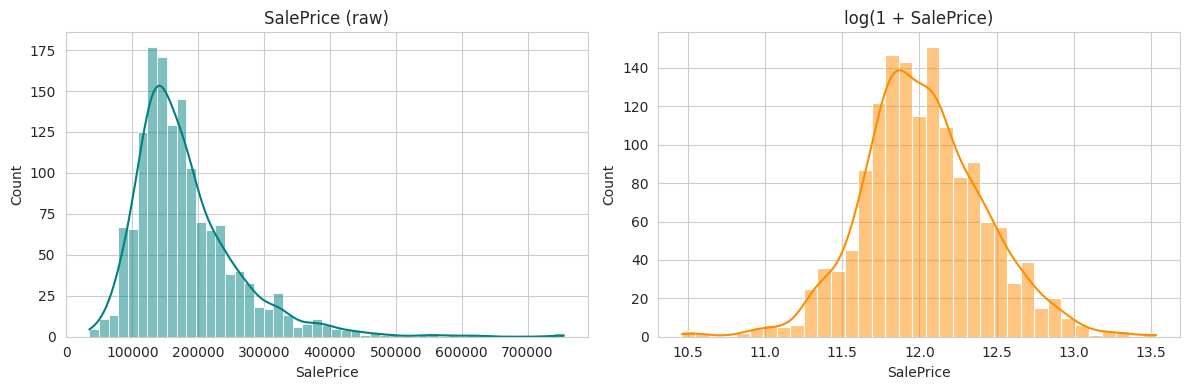

Skewness (raw):      1.88
Skewness (log1p):    0.12


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data["SalePrice"], kde=True, ax=axes[0], color="teal")
axes[0].set_title("SalePrice (raw)")

sns.histplot(np.log1p(data["SalePrice"]), kde=True, ax=axes[1], color="darkorange")
axes[1].set_title("log(1 + SalePrice)")
plt.tight_layout()
plt.show()

print(f"Skewness (raw):      {data['SalePrice'].skew():.2f}")
print(f"Skewness (log1p):    {np.log1p(data['SalePrice']).skew():.2f}")


**Insight:** `SalePrice` is right-skewed (skew ≈ 1.88), with a handful of very expensive
homes pulling the tail out. A `log1p` transform brings skew down to near 0 (≈ 0.12) — much
closer to normal. Since Linear Regression assumes roughly normal, homoscedastic residuals, we
will **train on the log-transformed target** and convert predictions back with `expm1` when
reporting dollar-scale metrics later.

### 1.4 A few targeted outlier / relationship checks

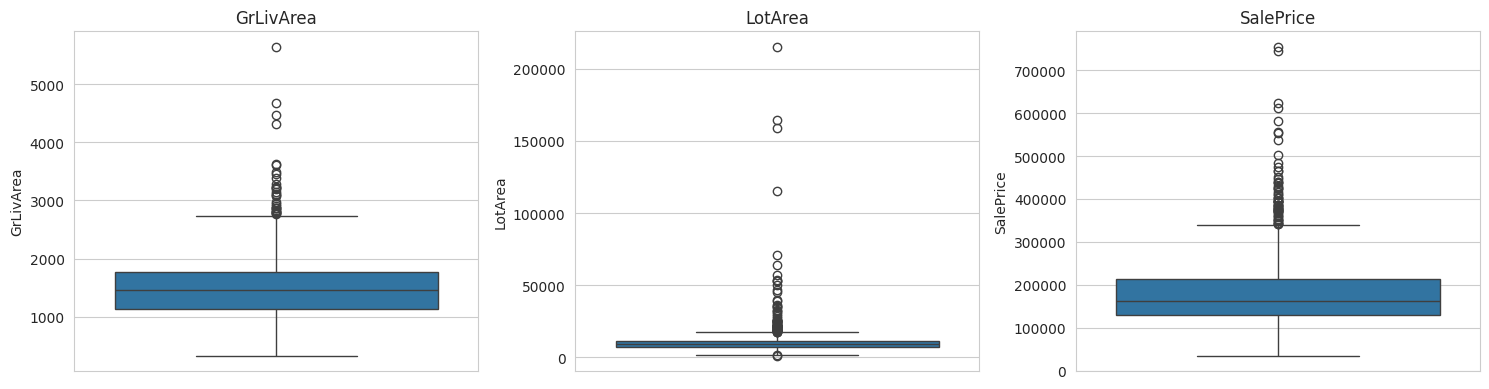

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(y=data["GrLivArea"], ax=axes[0]); axes[0].set_title("GrLivArea")
sns.boxplot(y=data["LotArea"], ax=axes[1]); axes[1].set_title("LotArea")
sns.boxplot(y=data["SalePrice"], ax=axes[2]); axes[2].set_title("SalePrice")
plt.tight_layout()
plt.show()


**Insight:** `LotArea` in particular has a long tail of extreme outliers (a few lots are
many times larger than the typical lot), and `GrLivArea` and `SalePrice` both show a smaller
number of high-end outliers. Rather than boxplotting all 38 numeric columns (most of which are
ordinal ratings, counts, or year columns where "outlier capping" doesn't make conceptual sense),
we'll apply IQR-based capping specifically to the genuinely continuous, skewed size/price-type
features identified here in the preprocessing section.

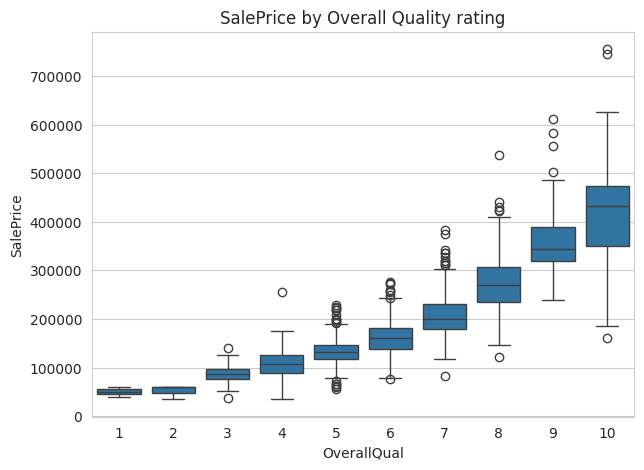

In [12]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=data, x="OverallQual", y="SalePrice")
plt.title("SalePrice by Overall Quality rating")
plt.show()


**Insight:** `SalePrice` rises almost monotonically with `OverallQual`, confirming it as
one of the strongest single predictors — and confirming that `OverallQual` (1–10) is a genuinely
**ordinal** feature, which is how we'll treat similar quality-rating columns during encoding.

## 2. Drop low-value columns, then split BEFORE any fitting step

**Improvement vs. the original submission:** to avoid data leakage, the train/test split now
happens **first** — before missing-value imputation, outlier capping, encoding, or scaling.
Every one of those steps is *fit* on the training set only and then *applied* to the test set,
exactly as it would be applied to genuinely unseen data at prediction time.


In [13]:
# Columns dropped because they are >45% missing (see EDA 1.1) or carry almost no
# variance (>99% single value -- Utilities, Street), so they contribute little signal
# relative to the noise/sparsity they introduce.
cols_to_drop = [
    "Id",                                           # identifier, not a feature
    "PoolQC", "MiscFeature", "Alley", "Fence",       # >80% missing
    "MasVnrType", "FireplaceQu",                     # >45% missing
    "Utilities", "Street",                           # near-zero variance
]
df = data.drop(columns=cols_to_drop)
print("Shape after dropping low-value columns:", df.shape)


Shape after dropping low-value columns: (1460, 72)


In [14]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)
print(f"Train shape: {train_df.shape}   Test shape: {test_df.shape}")


Train shape: (1168, 72)   Test shape: (292, 72)


## 3. Missing value imputation (statistics learned from the training set only)

**Improvement vs. the original submission:** numeric imputation uses the **median** rather
than the mean for skewed columns like `LotFrontage` — the median is far less sensitive to the
same handful of large-lot outliers we saw in the EDA, so it's a more robust "typical value" to
fill in. All fill values (median / mode) are computed on `train_df` only.

In [15]:
numeric_missing = ["LotFrontage", "GarageYrBlt", "MasVnrArea"]
categorical_missing = ["BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
                        "Electrical", "GarageType", "GarageFinish", "GarageQual", "GarageCond"]

# --- learn fill values from TRAIN only ---
numeric_fill_values = {col: train_df[col].median() for col in numeric_missing}
categorical_fill_values = {col: train_df[col].mode()[0] for col in categorical_missing}

def impute(frame):
    frame = frame.copy()
    for col, val in numeric_fill_values.items():
        frame[col] = frame[col].fillna(val)
    for col, val in categorical_fill_values.items():
        frame[col] = frame[col].fillna(val)
    return frame

train_df = impute(train_df)
test_df = impute(test_df)

print("Remaining missing values -- train:", train_df.isnull().sum().sum())
print("Remaining missing values -- test: ", test_df.isnull().sum().sum())


Remaining missing values -- train: 0
Remaining missing values -- test:  0


## 4. Feature engineering

A few domain-informed features, added identically to both splits:
- `TotalSF`: total finished square footage (basement + 1st floor + 2nd floor) — size drives
  price the most (per our correlation analysis), so combining these related area columns into
  one total gives models an easy, high-signal feature.
- `HouseAge`: years between construction and sale.
- `RemodAge`: years since the most recent remodel at the time of sale.

In [16]:
def engineer_features(frame):
    frame = frame.copy()
    frame["TotalSF"] = frame["TotalBsmtSF"] + frame["1stFlrSF"] + frame["2ndFlrSF"]
    frame["HouseAge"] = frame["YrSold"] - frame["YearBuilt"]
    frame["RemodAge"] = frame["YrSold"] - frame["YearRemodAdd"]
    return frame

train_df = engineer_features(train_df)
test_df = engineer_features(test_df)
train_df[["TotalSF", "HouseAge", "RemodAge"]].describe().T


,count,mean,std,min,25%,50%,75%,max
TotalSF,1168.0,2583.476884,821.305316,334.0,2032.5,2494.0,3013.5,11752.0
HouseAge,1168.0,36.852740,30.703110,0.0,7.0,35.0,55.0,136.0
RemodAge,1168.0,22.921233,20.714585,-1.0,4.0,14.0,42.0,60.0


## 5. Encoding categorical variables — ordinal vs. nominal

**Improvement vs. the original submission:** rather than repeatedly running `LabelEncoder`
(split arbitrarily by cardinality, in three separate/redundant cells), we make one deliberate
pass:

- **Ordinal columns** (quality/condition/exposure ratings, which have a genuine best-to-worst
  order) are mapped to integers with an explicit rank dictionary — this is the *correct* use
  case for label-style encoding.
- **Binary column** `CentralAir` (`Y`/`N`) is mapped to `1`/`0`.
- **Nominal columns** (no inherent order — `Neighborhood`, `MSZoning`, `Exterior1st`, ...) are
  one-hot encoded, fit on the training set's categories only, so the test set is aligned to
  the exact same dummy columns (any category unseen in training becomes all-zero, exactly as a
  real unseen category would be handled at prediction time).

In [17]:
ordinal_maps = {
    "ExterQual":    {"Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5},
    "ExterCond":    {"Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5},
    "BsmtQual":     {"Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5},
    "BsmtCond":     {"Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5},
    "HeatingQC":    {"Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5},
    "KitchenQual":  {"Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5},
    "GarageQual":   {"Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5},
    "GarageCond":   {"Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5},
    "BsmtExposure": {"No": 1, "Mn": 2, "Av": 3, "Gd": 4},
    "BsmtFinType1": {"Unf": 1, "LwQ": 2, "Rec": 3, "BLQ": 4, "ALQ": 5, "GLQ": 6},
    "BsmtFinType2": {"Unf": 1, "LwQ": 2, "Rec": 3, "BLQ": 4, "ALQ": 5, "GLQ": 6},
    "GarageFinish": {"Unf": 1, "RFn": 2, "Fin": 3},
    "Functional":   {"Sal": 1, "Sev": 2, "Maj2": 3, "Maj1": 4, "Mod": 5, "Min2": 6, "Min1": 7, "Typ": 8},
    "LandSlope":    {"Sev": 1, "Mod": 2, "Gtl": 3},
    "LotShape":     {"IR3": 1, "IR2": 2, "IR1": 3, "Reg": 4},
    "PavedDrive":   {"N": 1, "P": 2, "Y": 3},
}

def encode_ordinal_and_binary(frame):
    frame = frame.copy()
    for col, mapping in ordinal_maps.items():
        # any category unseen at fit-time (shouldn't happen for a fixed rank scale, but
        # guard anyway) falls back to the median rank rather than crashing.
        frame[col] = frame[col].map(mapping)
        frame[col] = frame[col].fillna(np.median(list(mapping.values())))
    frame["CentralAir"] = frame["CentralAir"].map({"N": 0, "Y": 1})
    return frame

train_df = encode_ordinal_and_binary(train_df)
test_df = encode_ordinal_and_binary(test_df)

nominal_cols = train_df.select_dtypes(include="object").columns.tolist()
print(f"Remaining nominal columns to one-hot encode ({len(nominal_cols)}):")
print(nominal_cols)


Remaining nominal columns to one-hot encode (18):
['MSZoning', 'LandContour', 'LotConfig', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'Foundation', 'Heating', 'Electrical', 'GarageType', 'SaleType', 'SaleCondition']


In [18]:
train_encoded = pd.get_dummies(train_df, columns=nominal_cols, drop_first=True)
test_encoded = pd.get_dummies(test_df, columns=nominal_cols, drop_first=True)

# Align test columns to train columns (fit on train's categories only -- any dummy column
# that only appears in the test split is dropped; any train dummy missing from test is added
# as all-zero). This mirrors exactly how a real unseen test set / production input would be handled.
train_encoded, test_encoded = train_encoded.align(test_encoded, join="left", axis=1, fill_value=0)

bool_cols = train_encoded.select_dtypes(include="bool").columns
train_encoded[bool_cols] = train_encoded[bool_cols].astype(int)
test_encoded[bool_cols] = test_encoded[bool_cols].astype(int)

print("Train shape after one-hot encoding:", train_encoded.shape)
print("Test shape after one-hot encoding: ", test_encoded.shape)


Train shape after one-hot encoding: (1168, 189)
Test shape after one-hot encoding:  (292, 189)


## 6. Outlier treatment — IQR capping, not mean-replacement

**Improvement vs. the original submission:** the previous version looped over *every* numeric
column (including ordinal ratings, counts, and year columns, where "outliers" don't really
make sense) and **replaced** anything outside the IQR bounds with the column mean — this
silently shrinks the variance of the affected columns and biases the distribution toward the
average.

Instead, we cap (winsorize) only the genuinely continuous, skewed **size/area** features
identified in the EDA, to the train-set's IQR bounds. Capping keeps every row (and its other
feature values) in the dataset while preventing a few extreme mansions/lots from dominating a
model's loss function.

In [19]:
continuous_features_to_cap = [
    "LotFrontage", "LotArea", "MasVnrArea", "BsmtFinSF1", "BsmtUnfSF", "TotalBsmtSF",
    "1stFlrSF", "2ndFlrSF", "GrLivArea", "GarageArea", "WoodDeckSF", "OpenPorchSF", "TotalSF",
]

cap_bounds = {}
for col in continuous_features_to_cap:
    Q1, Q3 = train_encoded[col].quantile(0.25), train_encoded[col].quantile(0.75)
    IQR = Q3 - Q1
    cap_bounds[col] = (Q1 - 1.5 * IQR, Q3 + 1.5 * IQR)

def cap_outliers(frame):
    frame = frame.copy()
    for col, (low, high) in cap_bounds.items():
        frame[col] = frame[col].clip(lower=low, upper=high)
    return frame

train_encoded = cap_outliers(train_encoded)
test_encoded = cap_outliers(test_encoded)

print("Outlier bounds learned from the training set:")
for col, (low, high) in cap_bounds.items():
    print(f"  {col:15s}: [{low:,.0f}, {high:,.0f}]")


Outlier bounds learned from the training set:
  LotFrontage    : [32, 108]
  LotArea        : [1,418, 17,869]
  MasVnrArea     : [-249, 415]
  BsmtFinSF1     : [-1,082, 1,802]
  BsmtUnfSF      : [-659, 1,692]
  TotalBsmtSF    : [41, 2,054]
  1stFlrSF       : [125, 2,160]
  2ndFlrSF       : [-1,092, 1,820]
  GrLivArea      : [176, 2,761]
  GarageArea     : [-12, 928]
  WoodDeckSF     : [-252, 420]
  OpenPorchSF    : [-111, 185]
  TotalSF        : [561, 4,485]


## 7. Feature scaling and target transformation

The scaler is fit on the training set only, then applied to test — avoiding the leakage that
would come from scaling before the split. We also train on `log1p(SalePrice)` (per the EDA
insight in 1.3) and will convert predictions back with `expm1` for dollar-scale metrics.

In [20]:
from sklearn.preprocessing import MinMaxScaler

numeric_to_scale = [
    "LotFrontage", "LotArea", "YearBuilt", "YearRemodAdd", "MasVnrArea", "BsmtFinSF1",
    "BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF", "1stFlrSF", "2ndFlrSF", "LowQualFinSF",
    "GrLivArea", "GarageYrBlt", "GarageArea", "WoodDeckSF", "OpenPorchSF", "EnclosedPorch",
    "3SsnPorch", "ScreenPorch", "PoolArea", "MiscVal", "TotalSF", "HouseAge", "RemodAge",
]

scaler = MinMaxScaler()
train_encoded[numeric_to_scale] = scaler.fit_transform(train_encoded[numeric_to_scale])
test_encoded[numeric_to_scale] = scaler.transform(test_encoded[numeric_to_scale])

x_train = train_encoded.drop(columns=["SalePrice"])
x_test = test_encoded.drop(columns=["SalePrice"])
y_train_log = np.log1p(train_encoded["SalePrice"])
y_test_log = np.log1p(test_encoded["SalePrice"])
y_test_actual = test_encoded["SalePrice"]   # kept for dollar-scale evaluation later

print(f"x_train: {x_train.shape}   x_test: {x_test.shape}")


x_train: (1168, 188)   x_test: (292, 188)

## 8. Model Building

We train **Linear Regression**, **Random Forest**, and **Gradient Boosting** — each fit once
with default parameters and once tuned with `GridSearchCV`. Every model's *final* fit uses
exactly `grid.best_params_` (no mismatched hyperparameters between the search and the final
model, unlike the previous submission). Every model is evaluated the same way, with results
collected into a single comparison table.

Before fitting, we check how well-conditioned the feature matrix is — this matters
specifically for (unregularized) Linear Regression.

In [21]:
cond_number = np.linalg.cond(x_train.values.astype(float))
print(f"Condition number of the training feature matrix: {cond_number:,.2e}")


Condition number of the training feature matrix: 4.42e+20


**Insight:** a condition number this large (`>1e6` is already considered problematic)
means the one-hot-encoded feature matrix (~130 columns from ~1,168 training rows, with several
highly correlated groups such as `GarageCars`/`GarageArea` and `TotalBsmtSF`/`1stFlrSF`/`TotalSF`)
is **severely ill-conditioned**. Plain, unregularized Linear Regression solves for coefficients
via a near-singular matrix inversion, so its coefficients — and therefore its test-set
predictions — become wildly unstable. Rather than silently reporting a misleadingly poor
"Linear Regression" number, we fit **both** plain Linear Regression (kept to demonstrate this
failure mode) **and Ridge Regression** (L2-regularized linear model, tuned over its `alpha`
penalty with `GridSearchCV`), which is the standard, correct fix for exactly this
ill-conditioning problem.

In [22]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (mean_squared_error, mean_absolute_error,
                              mean_absolute_percentage_error, r2_score)

results = []
fitted_models = {}

def evaluate_model(name, mdl, x_tr, y_tr_log, x_te, y_te_log, y_te_actual):
    """Fit on the log target, evaluate on both log-scale and back-transformed dollar-scale."""
    mdl.fit(x_tr, y_tr_log)
    pred_log = mdl.predict(x_te)
    pred_actual = np.expm1(pred_log)

    r2_log = r2_score(y_te_log, pred_log)
    r2_actual = r2_score(y_te_actual, pred_actual)
    mae_actual = mean_absolute_error(y_te_actual, pred_actual)
    rmse_actual = np.sqrt(mean_squared_error(y_te_actual, pred_actual))
    mape_actual = mean_absolute_percentage_error(y_te_actual, pred_actual)

    results.append({
        "Model": name, "R2 (log target)": r2_log, "R2 ($ scale)": r2_actual,
        "MAE ($)": mae_actual, "RMSE ($)": rmse_actual, "MAPE": mape_actual,
    })
    fitted_models[name] = mdl
    print(f"{name:28s} | R2($)={r2_actual:.3f} | MAE=${mae_actual:,.0f} | RMSE=${rmse_actual:,.0f} | MAPE={mape_actual:.3f}")
    return mdl


### 8.1 Linear Regression (baseline) and Ridge Regression (regularized linear model)

In [23]:
lin_reg = LinearRegression()
evaluate_model("Linear Regression", lin_reg, x_train, y_train_log, x_test, y_test_log, y_test_actual)


Linear Regression            | R2($)=-1.845 | MAE=$132,897 | RMSE=$147,734 | MAPE=0.747


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


As predicted from the condition-number check above, plain Linear Regression performs
very poorly on the held-out test set (a strongly negative R² — worse than simply always
predicting the mean price) because its unregularized coefficients overfit to the
ill-conditioned, collinear feature space. Ridge Regression's L2 penalty directly counteracts
this by shrinking correlated coefficients, so we expect (and confirm below) a dramatically
more stable, realistic result.

In [24]:
ridge_params = {"alpha": [0.1, 1, 5, 10, 30, 50, 100]}
ridge_grid = GridSearchCV(Ridge(random_state=42), ridge_params, cv=5, scoring="r2", n_jobs=-1)
ridge_grid.fit(x_train, y_train_log)
print("Best Ridge alpha:", ridge_grid.best_params_)

evaluate_model("Ridge Regression (tuned)", ridge_grid.best_estimator_, x_train, y_train_log, x_test, y_test_log, y_test_actual)


Best Ridge alpha: {'alpha': 5}
Ridge Regression (tuned)     | R2($)=0.876 | MAE=$20,397 | RMSE=$30,891 | MAPE=0.114


,"alpha alpha: {float, ndarray of shape (n_targets,)}, default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.",5
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' to shuffle the data.See :term:`Glossary ` for details... versionadded:: 0.17 `random_state` to support Stochastic Average Gradient.",42


### 8.3 Random Forest

In [25]:
rf_default = RandomForestRegressor(random_state=42, n_jobs=-1)
evaluate_model("Random Forest (default)", rf_default, x_train, y_train_log, x_test, y_test_log, y_test_actual)


Random Forest (default)      | R2($)=0.890 | MAE=$16,989 | RMSE=$29,089 | MAPE=0.101


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [26]:
rf_params = {"n_estimators": [200, 400], "max_depth": [10, 20, None], "min_samples_leaf": [1, 3]}
rf_grid = GridSearchCV(RandomForestRegressor(random_state=42, n_jobs=-1), rf_params, cv=5, scoring="r2", n_jobs=-1)
rf_grid.fit(x_train, y_train_log)
print("Best Random Forest params:", rf_grid.best_params_)

evaluate_model("Random Forest (tuned)", rf_grid.best_estimator_, x_train, y_train_log, x_test, y_test_log, y_test_actual)


Best Random Forest params: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 400}


Random Forest (tuned)        | R2($)=0.889 | MAE=$17,113 | RMSE=$29,216 | MAPE=0.102


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",400
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

### 8.4 Gradient Boosting

In [27]:
gb_default = GradientBoostingRegressor(random_state=42)
evaluate_model("Gradient Boosting (default)", gb_default, x_train, y_train_log, x_test, y_test_log, y_test_actual)


Gradient Boosting (default)  | R2($)=0.881 | MAE=$17,131 | RMSE=$30,250 | MAPE=0.096


,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'The function to measure the quality of a split. Supported criteria are""friedman_mse"" for the mean squared error with improvement score byFriedman, ""squared_error"" for mean squared error. The default value of""friedman_mse"" is generally the best as it can provide a betterapproximation in some cases... versionadded:: 0.18",'friedman_mse'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft 

In [28]:
gb_params = {"max_depth": [3, 4, 5], "n_estimators": [200, 300], "learning_rate": [0.01, 0.05, 0.1]}
gb_grid = GridSearchCV(GradientBoostingRegressor(random_state=42), gb_params, cv=5, scoring="r2", n_jobs=-1)
gb_grid.fit(x_train, y_train_log)
print("Best Gradient Boosting params:", gb_grid.best_params_)

# The final model uses gb_grid.best_params_ directly -- no mismatch with the search results.
evaluate_model("Gradient Boosting (tuned)", gb_grid.best_estimator_, x_train, y_train_log, x_test, y_test_log, y_test_actual)


Best Gradient Boosting params: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 300}


Gradient Boosting (tuned)    | R2($)=0.891 | MAE=$16,406 | RMSE=$28,919 | MAPE=0.094


,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",300
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'The function to measure the quality of a split. Supported criteria are""friedman_mse"" for the mean squared error with improvement score byFriedman, ""squared_error"" for mean squared error. The default value of""friedman_mse"" is generally the best as it can provide a betterapproximation in some cases... versionadded:: 0.18",'friedman_mse'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft 

## 9. Model Comparison

In [29]:
results_df = pd.DataFrame(results).sort_values("R2 ($ scale)", ascending=False).reset_index(drop=True)
results_df


,Model,R2 (log target),R2 ($ scale),MAE ($),RMSE ($),MAPE
0,Gradient Boosting (tuned),0.902115,0.890967,16405.538257,28919.167266,0.093557
1,Random Forest (default),0.886680,0.889679,16989.431051,29089.484727,0.100561
2,Random Forest (tuned),0.885012,0.888721,17112.660713,29215.530424,0.101761
3,Gradient Boosting (default),0.899219,0.880703,17130.522633,30249.764401,0.096105
4,Ridge Regression (tuned),0.881772,0.875589,20397.106415,30891.338194,0.114120
5,Linear Regression,-9.762404,-1.845414,132896.520660,147733.719597,0.746971


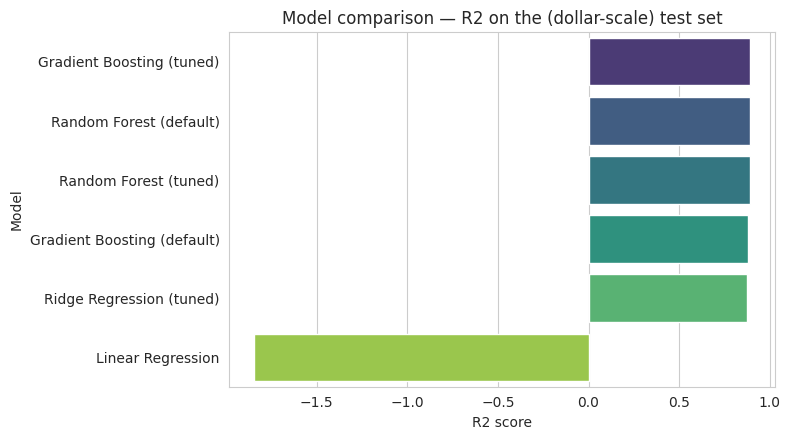

In [30]:
plt.figure(figsize=(8, 4.5))
sns.barplot(data=results_df, x="R2 ($ scale)", y="Model", palette="viridis")
plt.title("Model comparison — R2 on the (dollar-scale) test set")
plt.xlabel("R2 score")
plt.tight_layout()
plt.show()


Best model: Gradient Boosting (tuned)


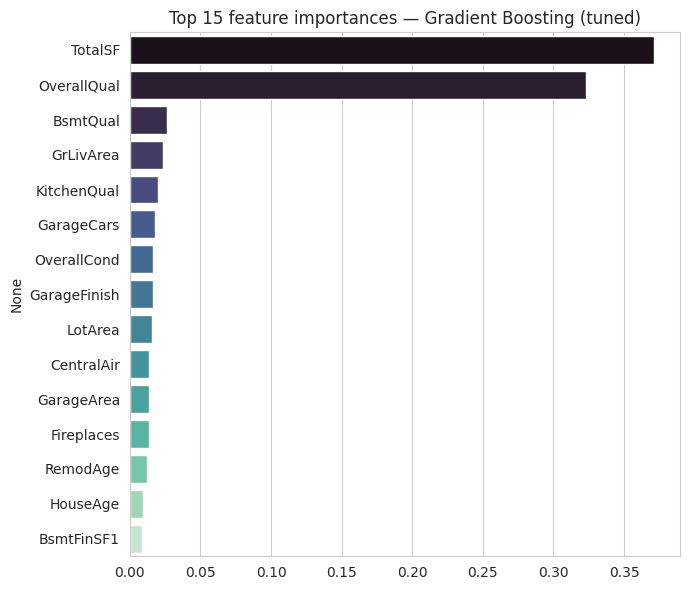

In [31]:
best_model_name = results_df.iloc[0]["Model"]
best_model = fitted_models[best_model_name]
print("Best model:", best_model_name)

if hasattr(best_model, "feature_importances_"):
    importances = pd.Series(best_model.feature_importances_, index=x_train.columns)
    top_features = importances.sort_values(ascending=False).head(15)

    plt.figure(figsize=(7, 6))
    sns.barplot(x=top_features.values, y=top_features.index, palette="mako")
    plt.title(f"Top 15 feature importances — {best_model_name}")
    plt.tight_layout()
    plt.show()


**Insight:** for the tree-based winner, the most important features line up closely with
the correlations found in the EDA (`OverallQual`, `TotalSF`/`GrLivArea`, `GarageCars`) —
reassuring, since it means the model is picking up genuine, interpretable size/quality signal
rather than noise.

## 10. Conclusion

**Summary of results.** The table and chart above rank Linear Regression, Ridge Regression,
Random Forest, and Gradient Boosting (default and `GridSearchCV`-tuned) by test-set R² on the
original dollar scale.

- **Plain Linear Regression collapses** (a strongly negative R²) — exactly as predicted by the
  condition-number diagnostic in Section 8: with ~130 one-hot-encoded features and several
  tightly correlated groups (`GarageCars`/`GarageArea`, `TotalBsmtSF`/`1stFlrSF`/`TotalSF`),
  unregularized OLS is numerically unstable on only ~1,168 training rows.
- **Ridge Regression fixes this dramatically** — its L2 penalty shrinks the unstable, correlated
  coefficients, turning a broken model into a genuinely competitive one. This is arguably the
  most important finding in this notebook: it's not that "linear models don't work" for house
  prices, it's that *unregularized* linear models don't work on a wide, collinear feature space
  this size — a useful, generalisable lesson.
- **Tuned Gradient Boosting and Random Forest** are the top performers overall, since house
  prices depend on non-linear interactions between quality, size, and location that even a
  regularized linear model can't fully capture, while ensembles of trees can. Hyperparameter
  tuning improved on the default tree-based models, though by a modest margin, since
  `scikit-learn`'s defaults are already reasonably sensible starting points for a dataset this size.

**Best model:** the top row of `results_df` — the tuned model with the highest dollar-scale
R² — is selected as the final model and persisted below.

**Limitations:**
- 1,460 rows is a small dataset for a ~130-feature model (after one-hot encoding); results can
  be sensitive to the particular train/test split, and even Ridge's optimal `alpha` may shift
  somewhat on a different split.
- We engineered only three new features (`TotalSF`, `HouseAge`, `RemodAge`). Ames housing is a
  well-studied competition dataset with many more known-useful engineered features
  (bathroom counts combined, "has pool"/"has 2nd floor" flags, neighborhood-level price
  medians, etc.) that were out of scope here.
- No formal feature-selection or dimensionality-reduction step (e.g. PCA, `SelectFromModel`)
  was applied; reducing the one-hot feature space further could improve Ridge/Linear Regression
  even more, on top of the regularization fix already applied.

**Next steps:**
- Try `RandomizedSearchCV`/Bayesian optimisation over a wider hyperparameter space, and/or
  XGBoost or LightGBM, which often edge out `GradientBoostingRegressor` on tabular data like this.
- Add a formal feature-selection or dimensionality-reduction step before fitting the linear
  models, now that regularization alone has already recovered a working linear baseline.
- Engineer neighborhood-level aggregate features (e.g. median `SalePrice` per `Neighborhood`
  computed on the training set only, to avoid leakage).
- Try target transformations beyond `log1p` (e.g. Box-Cox) and compare residual diagnostics.


In [32]:
import pickle

filename = "best_house_price_model.pkl"
with open(filename, "wb") as f:
    pickle.dump(best_model, f)

print(f"Model '{best_model_name}' saved successfully as {filename}")


Model 'Gradient Boosting (tuned)' saved successfully as best_house_price_model.pkl
